# 🥁 Drum OMR — Qwen3-VL fine-tune (trial)

Teaches a small vision-language model to read one bar of drum notation and write it as text:

```
0:eighth:hi_hat_closed+kick 4:eighth:hi_hat_closed 8:eighth:hi_hat_closed+snare ...
```

Same bars and same song split as the MobileNetV3 baseline (`baseline-14drum-v1`, 12.5%
of held-out bars read perfectly), so the final number is directly comparable.

**Before running**
1. On the Mac: `python3 ml/omr/prepare_finetune.py --train-bars 3000 --zip`
2. Upload `ml/data/finetune.zip` to `MyDrive/drumhub/finetune.zip`
3. Runtime → Change runtime type → **T4 GPU**, then Run all

If Colab disconnects mid-training, run all again: training resumes from the last saved step.

In [1]:
# 1. Install Unsloth (LoRA fine-tuning for vision models)
%pip install -q unsloth

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.3/81.3 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.1/26.1 MB 80.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 121.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 98.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 115.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 115.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199

In [2]:
# 2. Settings, Drive, and the data package
from google.colab import drive
drive.mount('/content/drive')

import json, sys, zipfile
from pathlib import Path

MODEL = 'unsloth/Qwen3-VL-8B-Instruct-unsloth-bnb-4bit'  # biggest that fits a T4; the 2B/4B are the on-device options
EPOCHS = 2
IMAGE_SCALE = 2      # bars are only ~356x146 px; enlarging gives the model more to see per notehead
EVAL_BARS = 300      # evenly spread test bars to score; None scores all 2,184 (slow)
MAX_NEW_TOKENS = 512 # the longest bar in the data is ~700 characters

DRIVE_ROOT = Path('/content/drive/MyDrive/unsloth')
RUN_DIR = DRIVE_ROOT / 'qwen-omr' / MODEL.split('/')[-1]
RUN_DIR.mkdir(parents=True, exist_ok=True)

ROOT = Path('/content/drumhub')
if not (ROOT / '.complete').exists():
    with zipfile.ZipFile(DRIVE_ROOT / 'finetune.zip') as archive:
        archive.extractall(ROOT)
    (ROOT / '.complete').touch()

sys.path.insert(0, str(ROOT / 'ml' / 'omr'))
from prepare_finetune import decode_text  # the same parser the app side uses

PROMPT = (ROOT / 'ml/data/finetune/prompt.txt').read_text().strip()
print(PROMPT)

Mounted at /content/drive
Transcribe this single 4/4 bar of drum notation. Write one item per hit in time order as slot:duration:drums, where slot is the 32nd-note position 0-31 and drums are joined with +. Write only the items, separated by spaces. If the bar has no hits, write rest.


Train bars: 3000   Test bars: 2184
0:eighth:kick+crash 4:eighth:kick+crash 8:eighth:snare+crash 12:eighth:kick+crash 16:sixteenth:snare+kick 18:sixteenth:snare 20:sixteenth:kick+tom_hi 22:sixteenth:tom_hi 24:sixteenth:snare+kick 26:sixteenth:snare 28:sixteenth:kick+tom_mid 30:sixteenth:tom_mid


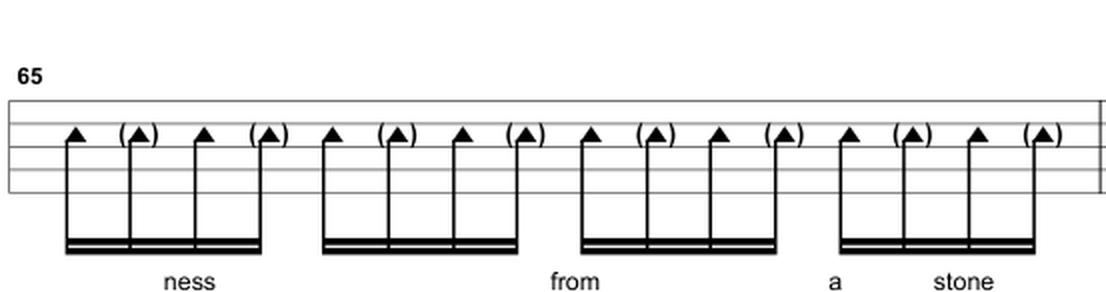

In [3]:
# 3. Load the image -> text pairs
from PIL import Image


def read_split(name):
    with (ROOT / 'ml/data/finetune' / f'{name}.jsonl').open() as source:
        return [json.loads(line) for line in source]


def load_image(row):
    image = Image.open(ROOT / row['image']).convert('RGB')
    return image.resize((image.width * IMAGE_SCALE, image.height * IMAGE_SCALE), Image.LANCZOS)


def to_conversation(row):
    return {'messages': [
        {'role': 'user', 'content': [{'type': 'text', 'text': PROMPT},
                                     {'type': 'image', 'image': load_image(row)}]},
        {'role': 'assistant', 'content': [{'type': 'text', 'text': row['target']}]},
    ]}


train_rows, test_rows = read_split('train'), read_split('test')
train_data = [to_conversation(row) for row in train_rows]
print(f'Train bars: {len(train_data)}   Test bars: {len(test_rows)}')
print(train_rows[10]['target'])
train_data[10]['messages'][0]['content'][1]['image']

In [4]:
# 4. Load Qwen3-VL in 4-bit and attach a LoRA adapter
from unsloth import FastVisionModel

model, tokenizer = FastVisionModel.from_pretrained(
    MODEL, load_in_4bit=True, use_gradient_checkpointing='unsloth')

# Vision layers are trained too: telling toms apart is a seeing problem, not a wording one.
model = FastVisionModel.get_peft_model(
    model,
    finetune_vision_layers=True, finetune_language_layers=True,
    finetune_attention_modules=True, finetune_mlp_modules=True,
    r=16, lora_alpha=16, lora_dropout=0, bias='none', random_state=42)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.9.14: Fast Qwen3_Vl patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/750 [00:00<?, ?it/s]

Unsloth: Offloading embeddings to RAM to save 1.16 GB.


In [5]:
# 5. Train. Checkpoints go to Drive so a disconnect does not lose the run.
from unsloth.trainer import UnslothVisionDataCollator
from trl import SFTTrainer, SFTConfig

FastVisionModel.for_training(model)
trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    data_collator=UnslothVisionDataCollator(model, tokenizer),
    train_dataset=train_data,
    args=SFTConfig(
        per_device_train_batch_size=2,
        gradient_accumulation_steps=4,
        num_train_epochs=EPOCHS,
        learning_rate=2e-4,
        warmup_ratio=0.03,
        lr_scheduler_type='cosine',
        optim='adamw_8bit',
        weight_decay=0.01,
        logging_steps=10,
        save_strategy='steps', save_steps=100, save_total_limit=2,
        output_dir=str(RUN_DIR / 'checkpoints'),
        seed=42,
        report_to='none',
        # Required for vision fine-tuning:
        remove_unused_columns=False,
        dataset_text_field='',
        dataset_kwargs={'skip_prepare_dataset': True},
        max_length=2048,
    ),
)
resume = any((RUN_DIR / 'checkpoints').glob('checkpoint-*'))
stats = trainer.train(resume_from_checkpoint=resume)
model.save_pretrained(str(RUN_DIR / 'lora'))
tokenizer.save_pretrained(str(RUN_DIR / 'lora'))
print(f"Trained in {stats.metrics['train_runtime'] / 60:.0f} min. Adapter saved to {RUN_DIR / 'lora'}")

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Unsloth: Model does not have a default image size - using 512
Unsloth: not enough free memory for dataset tokenization workers (~1GB each); tokenizing in-process.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 3,000 | Num Epochs = 2 | Total steps = 750
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 51,346,944 of 8,818,470,640 (0.58% trained)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_cuda' is deprecated, please use 'torch.backends.cuda.is_built()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_cudnn' is deprecated, please use 'torch.backends.cudnn.is_available()'
  return original(name)
/usr/local/lib/python3.13

Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
10,3.150779
20,1.690660
30,0.326299
40,0.147882
50,0.096429
60,0.110785
70,0.075431
80,0.067582
90,0.070744
100,0.038775


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/unsloth/qwen-omr/Qwen3-VL-8B-Instruct-unsloth-bnb-4bit/checkpoints/checkpoint-100/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/unsloth/qwen-omr/Qwen3-VL-8B-Instruct-unsloth-bnb-4bit/checkpoints/checkpoint-200/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/unsloth/qwen-omr/Qwen3-VL-8B-Instruct-unsloth-bnb-4bit/checkpoints/checkpoint-300/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/unsloth/qwen-omr/Qwen3-VL-8B-Instruct-unsloth-bnb-4bit/checkpoints/checkpoint-400/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/unsloth/qwen-omr/Qwen3-VL-8B-Instruct-unsloth-bnb-4bit/checkpoints/checkpoint-500/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/unsloth/qwen-omr/Qwen3-VL-8B-In

Trained in 133 min. Adapter saved to /content/drive/MyDrive/unsloth/qwen-omr/Qwen3-VL-8B-Instruct-unsloth-bnb-4bit/lora


In [6]:
# 6. Score on held-out songs
import time

FastVisionModel.for_inference(model)
chat = tokenizer.apply_chat_template(
    [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': PROMPT}]}],
    add_generation_prompt=True)


def read_bar(row):
    inputs = tokenizer(load_image(row), chat, add_special_tokens=False, return_tensors='pt').to('cuda')
    output = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, use_cache=True)
    return tokenizer.decode(output[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True).strip()


def placed(notes):
    return [(note['position'], tuple(sorted(note['drums'])), note['duration']) for note in notes]


def events(notes):
    """Ordered (drums, duration) hits: the baseline's sequence-accuracy definition."""
    return [hit[1:] for hit in placed(notes)]


step = max(1, len(test_rows) // EVAL_BARS) if EVAL_BARS else 1
eval_rows = test_rows[::step]
results, started = [], time.time()
for index, row in enumerate(eval_rows, 1):
    text = read_bar(row)
    truth = decode_text(row['target'])
    try:
        notes = decode_text(text)
    except ValueError:
        notes = None  # unreadable output counts as a wrong bar
    results.append({
        'image': row['image'], 'target': row['target'], 'predicted': text,
        'malformed': notes is None,
        'sequence_match': notes is not None and events(notes) == events(truth),
        'exact_match': notes is not None and placed(notes) == placed(truth),
    })
    if index % 25 == 0:
        print(f"{index}/{len(eval_rows)}  sequence so far: {sum(r['sequence_match'] for r in results) / index:.1%}")

total = len(results)
summary = {
    'model': MODEL, 'train_bars': len(train_rows), 'epochs': EPOCHS, 'image_scale': IMAGE_SCALE,
    'bars_scored': total, 'songs_scored': len({row['song'] for row in eval_rows}),
    'sequence_accuracy': sum(r['sequence_match'] for r in results) / total,
    'exact_with_positions': sum(r['exact_match'] for r in results) / total,
    'malformed_outputs': sum(r['malformed'] for r in results),
    'seconds_per_bar': (time.time() - started) / total,
}
(RUN_DIR / 'eval_results.json').write_text(json.dumps({'summary': summary, 'bars': results}, indent=2))
print(json.dumps(summary, indent=2))
print('MobileNetV3 baseline on all 2,184 test bars: sequence accuracy 12.5%')

25/312  sequence so far: 64.0%
50/312  sequence so far: 72.0%
75/312  sequence so far: 70.7%
100/312  sequence so far: 73.0%
125/312  sequence so far: 74.4%
150/312  sequence so far: 78.7%
175/312  sequence so far: 80.0%
200/312  sequence so far: 75.5%
225/312  sequence so far: 76.9%
250/312  sequence so far: 74.8%
275/312  sequence so far: 72.4%
300/312  sequence so far: 71.7%
{
  "model": "unsloth/Qwen3-VL-8B-Instruct-unsloth-bnb-4bit",
  "train_bars": 3000,
  "epochs": 2,
  "image_scale": 2,
  "bars_scored": 312,
  "songs_scored": 25,
  "sequence_accuracy": 0.7243589743589743,
  "exact_with_positions": 0.7147435897435898,
  "malformed_outputs": 2,
  "seconds_per_bar": 13.731780068996626
}
MobileNetV3 baseline on all 2,184 test bars: sequence accuracy 12.5%


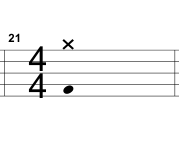

truth    : 0:whole:kick+crash
predicted: 0:quarter:kick+crash 



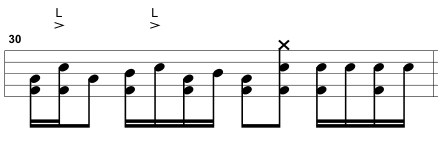

truth    : 0:sixteenth:kick+tom_mid 2:sixteenth:snare+kick 4:eighth:tom_mid 8:sixteenth:kick+tom_mid 10:sixteenth:snare 12:sixteenth:kick+tom_mid 14:sixteenth:tom_mid 16:eighth:kick+tom_mid 20:eighth:snare+kick+crash 24:sixteenth:snare+kick 26:sixteenth:snare 28:sixteenth:snare+kick 30:sixteenth:snare
predicted: 0:sixteenth:kick+floor_tom_1 2:sixteenth:kick+floor_tom_1 4:eighth:floor_tom_1 8:sixteenth:kick+floor_tom_1 10:sixteenth:floor_tom_1 12:sixteenth:kick+floor_tom_1 14:sixteenth:floor_tom_1 16:eighth:kick+floor_tom_1 20:eighth:kick+crash 24:sixteenth:kick+floor_tom_1 26:sixteenth:floor_tom_1 28:sixteenth:floor_tom_1 30:sixteenth:floor_tom_1 



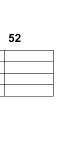

truth    : rest
predicted: 0:whole:snare 



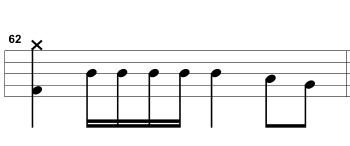

truth    : 0:quarter:kick+crash 8:sixteenth:tom_mid 10:sixteenth:tom_mid 12:sixteenth:tom_mid 14:sixteenth:tom_mid 16:quarter:tom_mid 24:eighth:tom_mid 28:eighth:floor_tom_1
predicted: 0:quarter:kick+crash 8:sixteenth:snare 10:sixteenth:snare 12:sixteenth:snare 14:sixteenth:snare 16:quarter:snare 24:eighth:floor_tom_1 28:eighth:floor_tom_1 



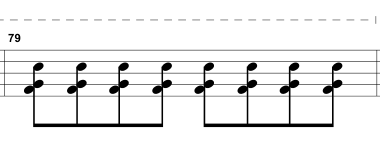

truth    : 0:eighth:snare+kick+floor_tom_1 4:eighth:snare+kick+floor_tom_1 8:eighth:snare+kick+floor_tom_1 12:eighth:snare+kick+floor_tom_1 16:eighth:snare+kick+floor_tom_1 20:eighth:snare+kick+floor_tom_1 24:eighth:snare+kick+floor_tom_1 28:eighth:snare+kick+floor_tom_1
predicted: 0:eighth:kick+tom_hi 4:eighth:kick+tom_hi 8:eighth:kick+tom_hi 12:eighth:kick+tom_hi 16:eighth:kick+tom_hi 20:eighth:kick+tom_hi 24:eighth:kick+tom_hi 28:eighth:kick+tom_hi 



In [7]:
# 7. Look at the first few misses
for result in [r for r in results if not r['sequence_match']][:5]:
    display(Image.open(ROOT / result['image']))
    print('truth    :', result['target'])
    print('predicted:', result['predicted'], '\n')